## Setup and functions (copied from `plots.ipynb`)

In [1]:
import glob
import os
import re
import zipfile
from functools import lru_cache
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.stats import spearmanr, wilcoxon
from aeon.visualisation import plot_critical_difference

# ---------------- Configuration ----------------
FIG_FULL = Path("./figs_thesis/3.2.1_treino_completo")
FIG_FULL.mkdir(parents=True, exist_ok=True)
SHOW_TITLES = False               # figure titles go in the LaTeX caption; set True to inspect the figures

# CodeCarbon start/stop adds a fixed overhead to every tracked block (fit, predict, predict_proba): measured at 3.09 s
# (median of 9 repeated calls, range 3.08-3.12 s; the first call of a process takes about 4.3 s). It is subtracted from
# the TabPFN train and predict (= inference) times below. Energy is not corrected: the overhead falls outside the
# measured window (an empty tracked block reports ~1e-7 kWh). Feature-extraction time is timed inside the tracker.
CORRECT_CODECARBON = True         # False: show the raw logged times
CODECARBON_OVERHEAD_S = 3.09 if CORRECT_CODECARBON else 0.0

# ---------------- Figure style (thesis) ----------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": True, "legend.framealpha": 0.92, "legend.facecolor": "white",   # boxed legends stay readable over the points
    "legend.edgecolor": "0.6", "legend.fancybox": False, "legend.borderpad": 0.5,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,        # embed fonts as TrueType (accepted by publishers)
})


def fig_title(fig, s, note_prefix="", **kw):
    """Figure title. In print mode only the `note_prefix` (e.g. the selection method) is kept; the caption carries the rest."""
    if SHOW_TITLES:
        fig.suptitle(s, **kw)
        return
    note = note_prefix.rstrip(", ")
    if note:
        fig.text(0.995, 0.995, note, ha="right", va="top", fontsize=8, color="0.35")


def boot_ci(v, n_boot=4000, seed=0, q=(2.5, 97.5)):
    """Mean and 95% bootstrap (percentile) CI over the elements of v (datasets)."""
    v = np.asarray(v, float)
    rng = np.random.default_rng(seed)
    means = v[rng.integers(0, len(v), (n_boot, len(v)))].mean(axis=1)
    return v.mean(), *np.percentile(means, q)

DECIMAL_COMMA = FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ","))

VERSIONS = ["2.5", "3.5"]
FEATURES = ["c22", "tsfresh", "multirocket"]
VCOLORS = {"2.5": "#4C78A8", "3.5": "#F58518"}          # color = TabPFN version
FMARKERS = {"c22": "o", "tsfresh": "s", "multirocket": "^"}   # marker = feature extractor
TOP_N = 10        # number of literature baselines shown in the comparisons (full-shot CD and few-shot vs full-shot)
MIN_COV = 0.8     # a baseline is only included if it covers >= 80% of the reference datasets (the redux ones cover 86%)

BENCHMARKS = {
    "redux": {
        "label": "univariate (redux)",
        "tabpfn_dir": Path("../full/redux"), "base_dir": Path("../full/redux"),
        "ref": None,
        "baselines": ["FreshPRINCE", "HC2", "H-InceptionTime", "MR-Hydra", "PF", "QUANT", "RDST", "WEASEL-2"],
    },
    "uea": {
        "label": "multivariate (UEA)",
        "tabpfn_dir": Path("../full/mv_core"), "base_dir": Path("../full/uea"),
        "ref": Path("../full/uea/accuracy/1NN-DTW-D_accuracy.csv"),
        "baselines": ["1NN-DTW-A", "1NN-DTW-D", "1NN-DTW-I", "Arsenal", "cBOSS", "CIF", "DrCIF", "HC1", "HC2",
                      "InceptionT", "MrSEQL", "MUSE", "ResNet", "RISE", "ROCKET", "RSF", "STC", "TapNet", "TDE", "TSF"],
    },
}

STATS = {
    "vram_total_mb": dict(
        ylabel="Total VRAM per dataset (MB, log scale)", title="VRAM usage distribution", fmt="{:.0f}",
        unit="MB", label="Total VRAM (MB)", head="VRAM usage",
        scatter="Per-dataset comparison\n(below the diagonal = 3.5 uses less VRAM)"),
    "inference_time": dict(
        ylabel="Time per dataset (s, log scale)", title="Time distribution", fmt="{:.1f}s",
        unit="s", label="Inference time (s)", head="Inference time",
        scatter="Per-dataset comparison\n(below the diagonal = 3.5 faster)"),
}


def save_full(fig, name):
    fig.savefig(FIG_FULL / f"{name}.pdf")


# ---------------- Loading ----------------
def _read(path):
    """Results CSV -> DataFrame (datasets x resample ids)."""
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str).str.replace(r"_(eq|nmv)$", "", regex=True)   # bake-off files keep the _eq/_nmv suffix
    df = df.select_dtypes(include="number")
    df.columns = [int(c) for c in df.columns]
    if Path(path).parent.name == "inference_time":              # inference time = predict_time, one CodeCarbon-tracked block
        df = (df - CODECARBON_OVERHEAD_S).clip(lower=0)
    return df


def score(path):
    """Per-dataset accuracy: mean over the resamples."""
    return _read(path).mean(axis=1)


def ref_datasets(cfg):
    """Reference-benchmark datasets (UEA: those that 1NN-DTW-D ran on); None = no filter."""
    return None if cfg["ref"] is None else _read(cfg["ref"]).mean(axis=1).dropna().index


def combine(scores, ref):
    df = pd.DataFrame(scores)
    if ref is not None:
        df = df.loc[df.index.intersection(ref)]
    return df.dropna()


def tabpfn_scores(cfg):
    return {f"{f}-TabPFN{v}": score(cfg["tabpfn_dir"] / "accuracy" / f"TabPFN{v}-{f}_accuracy.csv")
            for v in ["3.5", "2.5"] for f in FEATURES}


def load_cost(bench, stat):
    """{(version, feature): per-dataset Series} (mean over runs), filtered to the reference benchmark."""
    cfg = BENCHMARKS[bench]
    ref = ref_datasets(cfg)
    data = {}
    for v in VERSIONS:
        for f in FEATURES:
            p = cfg["tabpfn_dir"] / stat / f"TabPFN{v}-{f}_{stat}.csv"
            if not p.exists():
                print(f"Not found: {p}")
                continue
            s = _read(p).mean(axis=1)
            data[v, f] = s.reindex(ref).dropna() if ref is not None else s
    return data

In [2]:
def draw_cd(df, name, title):
    hl = {c: VCOLORS[c[-3:]] for c in df.columns if "TabPFN" in c}
    fig, ax = plot_critical_difference(df.to_numpy(), df.columns.tolist(), test="wilcoxon", alpha=0.05, highlight=hl)
    for t in ax.texts:                                   # decimal comma on the average ranks
        if re.fullmatch(r"\d+\.\d+", t.get_text()):
            t.set_text(t.get_text().replace(".", ","))
    fig_title(fig, f"{title} (n = {len(df)} datasets)", y=1.08)
    save_full(fig, name)
    plt.show()


def cd_tabpfn(bench):
    cfg = BENCHMARKS[bench]
    df = combine(tabpfn_scores(cfg), ref_datasets(cfg))
    print(f"[{bench}] datasets used: {len(df)}")
    draw_cd(df, f"cd_tabpfn_{bench}", f"TabPFN variants — {cfg['label']}")


def baseline_cd_table(bench, top_n=TOP_N, min_cov=MIN_COV, n_tabpfn=None):
    """Accuracy table (datasets x classifiers) used by the CD diagram vs baselines.
    `n_tabpfn`: keep only that many TabPFN variants (the ones with the best mean rank among the six); None keeps all six.
    Returns (table, kept baselines, excluded baselines, number of candidate baselines)."""
    cfg = BENCHMARKS[bench]
    ref = ref_datasets(cfg)
    tab = tabpfn_scores(cfg)
    idx = combine(tab, ref).index                       # datasets where all TabPFN variants exist
    base, cov = {}, {}
    for n in cfg["baselines"]:
        p = cfg["base_dir"] / "accuracy" / f"{n}_accuracy.csv"
        if p.exists():
            base[n] = score(p)
            cov[n] = base[n].reindex(idx).notna().mean()
    ok = {n: base[n].reindex(idx).mean() for n in base if cov[n] >= min_cov}
    top = sorted(ok, key=ok.get, reverse=True)[:top_n]
    excl = [f"{n} ({100 * cov[n]:.0f}%)" for n in base if cov[n] < min_cov]
    df = combine({**{n: base[n] for n in top}, **tab}, ref)
    if n_tabpfn is not None:                             # best TabPFN variants, by mean rank among the six
        ranks = df[list(tab)].rank(axis=1, ascending=False).mean()
        df = df[top + list(ranks.nsmallest(n_tabpfn).index)]
    return df, top, excl, len(base)


def cd_vs_baselines(bench, top_n=TOP_N, min_cov=MIN_COV, n_tabpfn=2):
    cfg = BENCHMARKS[bench]
    df, top, excl, n_all = baseline_cd_table(bench, top_n, min_cov, n_tabpfn)
    print(f"[{bench}] datasets used: {len(df)} | baselines: {len(top)} of {n_all} | TabPFN variants: {[c for c in df.columns if 'TabPFN' in c]}")
    if excl:
        print("  excluded for low dataset coverage:", ", ".join(excl))
    draw_cd(df, f"cd_baselines_{bench}", f"TabPFN × baselines (top {len(top)}) — {cfg['label']}")


In [3]:
# (imports already done in Part 0A)
# ---------------- Configuration ----------------
TABPFN_VERSION = "3.5"

FEW_DIR = Path("../few")
FULL_DIR = Path("../full")
RAW_DIR = Path("../../outputs/few")   # raw CSVs (they have class_coverage, n_support, n_pool)
FIG_FEW = Path("./figs_thesis/3.2.2_poucos_exemplos")
FIG_FEW.mkdir(parents=True, exist_ok=True)

METHODS = ["random", "stratified_random", "kmedoids", "stratified_kmedoids"]
KS = [1, 3, 5, 10]
FEW_CFGS = tuple(("stratified_kmedoids", k) for k in KS)   # few-shot configs compared with full-shot (every K)
RUNS = [0, 1, 2]

BENCH_CFG = {
    "redux": {"feature": "multirocket", "full_dir": "redux"},
    "uea": {"feature": "tsfresh", "full_dir": "mv_core"},
}
LABELS = {
    "random": "Random",
    "stratified_random": "Stratified Random",
    "kmedoids": "KMedoids",
    "stratified_kmedoids": "Stratified KMedoids",
}
COLORS = {
    "random": "#9ecae1",
    "stratified_random": "#3182bd",
    "kmedoids": "#fdae6b",
    "stratified_kmedoids": "#e6550d",
}
COST_METRICS = {
    "inference_time": "Inference time (s)",
    "vram_total_mb": "Total VRAM (MB)",
    "vram_data_mb": "Data VRAM (MB)",
}


def save_few(fig, name, bench):
    fig.savefig(FIG_FEW / f"{name}_{bench}.pdf")


# ---------------- Loading (the CSV reader `_read` is in Part 0A) ----------------
def load_few(method, k, bench, metric="accuracy"):
    p = FEW_DIR / method / f"K_{k}" / bench / metric / f"TabPFN-few_{method}_K{k}_{metric}.csv"
    return _read(p).reindex(columns=RUNS)


def load_full(bench, metric="accuracy"):
    cfg = BENCH_CFG[bench]
    p = FULL_DIR / cfg["full_dir"] / metric / f"TabPFN{TABPFN_VERSION}-{cfg['feature']}_{metric}.csv"
    return _read(p).reindex(columns=RUNS)


def load_metric(bench, metric):
    """(few, full_mean): few has columns (method, K, run); full_mean is the mean over the available full-shot runs."""
    fr = {}
    for m in METHODS:
        for k in KS:
            try:
                fr[(m, k)] = load_few(m, k, bench, metric)
            except FileNotFoundError as e:
                print("Not found:", e)
    return pd.concat(fr, axis=1).sort_index(axis=1), load_full(bench, metric).mean(axis=1)


class Ctx:
    """Data of one benchmark: accuracy (few, full_mean) and cost metrics (cost)."""

    def __init__(self, bench):
        self.bench = bench
        self.few, self.full_mean = load_metric(bench, "accuracy")
        self.cost = {met: load_metric(bench, met) for met in COST_METRICS}
        print(f"[{bench}] datasets in few-shot: {len(self.few)} | valid in ALL methods/K: {len(self.valid())}")
        for k in KS:
            print(f"  K={k}: {len(self.valid([k]))} valid datasets")

    def valid(self, ks=KS, methods=METHODS):
        """Datasets without NaN for all requested (method, K), that also exist in full-shot."""
        mask = [(c[0] in methods) and (c[1] in ks) for c in self.few.columns]
        return self.few.loc[:, mask].dropna().index.intersection(self.full_mean.dropna().index)

    def valid_cost(self, metric, ks=KS, methods=METHODS):
        """Datasets valid in accuracy and without NaN in the cost metric."""
        f, full = self.cost[metric]
        mask = [(c[0] in methods) and (c[1] in ks) for c in f.columns]
        return self.valid(ks, methods).intersection(f.loc[:, mask].dropna().index).intersection(full.dropna().index)

    def cost_ratio(self, metric, m, k, ds):
        f, full = self.cost[metric]
        return f.loc[ds, (m, k)].mean(axis=1) / full[ds]


_CTX = {}


def ctx(bench, reload=False):
    """Load the benchmark data once; `reload=True` rereads the CSVs."""
    if reload or bench not in _CTX:
        _CTX[bench] = Ctx(bench)
    return _CTX[bench]

In [4]:
def load_support_frac(bench, method, k):
    files = sorted(glob.glob(str(RAW_DIR / method / f"K_{k}" / f"results_{bench}_*.csv")))
    if not files:
        return None
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df["dataset"] = df["dataset"].astype(str)
    return df.groupby("dataset")[["n_support", "n_pool"]].first()


def plot_sample_efficiency(bench, method="stratified_kmedoids", n_bins=8):
    c = ctx(bench)
    rows = []
    for k in KS:
        sz = load_support_frac(bench, method, k)
        if sz is None:
            continue
        ds = c.valid([k], [method]).intersection(sz.index)
        acc_rel = c.few.loc[ds, (method, k)].mean(axis=1) / c.full_mean[ds]
        rows.append(pd.DataFrame({"K": k, "frac": sz.loc[ds, "n_support"] / sz.loc[ds, "n_pool"], "ret": acc_rel}))
    d = pd.concat(rows)
    cmap = plt.get_cmap("viridis")

    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    for i, k in enumerate(KS):
        r = d[d.K == k]
        ax.scatter(100 * r.frac, r.ret, s=16, alpha=0.5, color=cmap(i / max(len(KS) - 1, 1)), label=f"K={k}")
    edges = np.quantile(d.frac, np.linspace(0, 1, n_bins + 1))
    d["bin"] = pd.cut(d.frac, np.unique(edges), include_lowest=True)
    med = d.groupby("bin", observed=True).agg(x=("frac", "median"), y=("ret", "median"),
                                              q1=("ret", lambda s: s.quantile(0.25)), q3=("ret", lambda s: s.quantile(0.75)))
    ax.fill_between(100 * med.x, med.q1, med.q3, color="k", alpha=0.10, lw=0, label="Faixa interquartil")
    ax.plot(100 * med.x, med.y, "-s", color="k", lw=2, ms=5, label="Mediana por faixa", zorder=5)
    ax.axhline(1.0, ls=":", color="k", lw=1.2)
    ax.set_xscale("log")
    ax.set_xlabel("Fração do treino usada como conjunto de suporte (%)")
    ax.set_ylabel("Retenção")
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)
    fig_title(fig, f"Sample efficiency — {LABELS[method]}, {bench}")
    ax.grid(alpha=0.3, which="both")
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    save_few(fig, f"sample_efficiency_{method}", bench)
    plt.show()

In [5]:
# ---------------- Baselines (Ridge and 1NN) on the same support sets ----------------
BASE_RAW_DIR = Path("../../outputs/few_baseline")     # raw CSVs of exp/few_baseline: <model>/<method>/K_<k>/results_<bench>_*.csv
BASE_FOLDERS = {"Ridge": "ridge", "1NN": "1nn"}
MODELS3 = ["TabPFN", "Ridge", "1NN"]
MCOLORS = {"TabPFN": "#6a3d9a", "Ridge": "#1b9e77", "1NN": "#d95f02"}    # color = model


def _raw_files(bench, model, method, k):
    root = RAW_DIR / method if model == "TabPFN" else BASE_RAW_DIR / BASE_FOLDERS[model] / method
    return sorted(glob.glob(str(root / f"K_{k}" / f"results_{bench}_*.csv")))


def load_raw_model(bench, model, method, k):
    """Per-run rows (dataset, run, acc, coverage, K) of one model from its raw CSVs."""
    files = _raw_files(bench, model, method, k)
    if not files:
        return None
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    return pd.DataFrame({"dataset": df["dataset"].astype(str), "run": df["run"], "acc": df["accuracy"],
                         "coverage": df["class_coverage"], "K": k})


_MT = {}


def model_table(bench, reload=False):
    """Mean accuracy over runs, datasets x (model, method, K), for TabPFN (converted CSVs), Ridge and 1NN (raw CSVs)."""
    if reload or bench not in _MT:
        c = ctx(bench)
        cols = {}
        for m in METHODS:
            for k in KS:
                cols[("TabPFN", m, k)] = c.few[(m, k)].mean(axis=1)
                for model in BASE_FOLDERS:
                    r = load_raw_model(bench, model, m, k)
                    if r is not None:
                        cols[(model, m, k)] = r.groupby("dataset")["acc"].mean()
        t = pd.DataFrame(cols)
        t.columns = pd.MultiIndex.from_tuples(t.columns, names=["model", "method", "K"])
        _MT[bench] = t
    return _MT[bench]


def common_ds(bench):
    """Datasets with results for every (method, K) in TabPFN, Ridge and 1NN, and a full-shot reference."""
    return ctx(bench).valid().intersection(model_table(bench).dropna().index)


def plot_models_vs_k(bench, method="random"):
    """Relative accuracy vs K: TabPFN, Ridge and 1NN with one selection method (same datasets for every K)."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    fig, ax = plt.subplots(figsize=(5.2, 3.7))
    x = np.arange(len(KS))
    for model in MODELS3:
        mu, lo, hi = (np.array(s) for s in zip(*[boot_ci((t.loc[ds, (model, method, k)] / c.full_mean[ds]).values) for k in KS]))
        ax.plot(x, mu, "-o", color=MCOLORS[model], label=model)
        ax.fill_between(x, lo, hi, color=MCOLORS[model], alpha=0.15)
    ax.plot(x, np.ones(len(KS)), ":", color="k", lw=1.5, label="Treino completo")
    ax.set_xticks(x)
    ax.set_xticklabels([f"K={k}" for k in KS])
    ax.set_ylabel("Retenção")
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")
    fig_title(fig, f"Few-shot vs K — {LABELS[method]}, {bench} (n = {len(ds)} datasets, band = 95% bootstrap CI)")
    plt.tight_layout()
    save_few(fig, f"models_vs_k_{method}", bench)
    plt.show()


In [6]:
# ---------------- 3.2.3: selection of the support set ----------------
FIG_SEL = Path("./figs_thesis/3.2.3_selecao")
FIG_SEL.mkdir(parents=True, exist_ok=True)
PT_LABELS = {"random": "Aleatória", "stratified_random": "Aleatória estratificada",
             "kmedoids": "K-medoides", "stratified_kmedoids": "K-medoides estratificada"}


def plot_selection_by_model(bench):
    """Retention vs K, one panel per model; lines = support-set selection strategies."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    fig, axes = plt.subplots(1, len(MODELS3), figsize=(11, 3.7), sharey=True)
    x = np.arange(len(KS))
    for ax, model in zip(axes, MODELS3):
        for m in METHODS:
            mu, lo, hi = (np.array(s) for s in zip(*[boot_ci((t.loc[ds, (model, m, k)] / c.full_mean[ds]).values) for k in KS]))
            ax.plot(x, mu, "-o", color=COLORS[m], label=PT_LABELS[m])
            ax.fill_between(x, lo, hi, color=COLORS[m], alpha=0.15)
        ax.plot(x, np.ones(len(KS)), ":", color="k", lw=1.5, label="Treino completo")
        ax.set_xticks(x)
        ax.set_xticklabels([f"K={k}" for k in KS])
        ax.set_title(model)
        ax.yaxis.set_major_formatter(DECIMAL_COMMA)
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Retenção")
    axes[0].legend(loc="lower right")
    plt.tight_layout()
    fig.savefig(FIG_SEL / f"selecao_por_modelo_{bench}.pdf")
    plt.show()


def plot_label_gap(bench):
    """Retention gained by using the labels: stratified strategy minus its non-stratified counterpart, in p.p."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    pairs = [("random", "stratified_random"), ("kmedoids", "stratified_kmedoids")]
    fig, axes = plt.subplots(1, len(pairs), figsize=(9.2, 3.7), sharey=True)
    x = np.arange(len(KS))
    for ax, (base, strat) in zip(axes, pairs):
        for model in MODELS3:
            gaps = [100 * (t.loc[ds, (model, strat, k)] - t.loc[ds, (model, base, k)]) / c.full_mean[ds] for k in KS]
            mu, lo, hi = (np.array(s) for s in zip(*[boot_ci(g.values) for g in gaps]))
            ax.plot(x, mu, "-o", color=MCOLORS[model], label=model)
            ax.fill_between(x, lo, hi, color=MCOLORS[model], alpha=0.15)
        ax.axhline(0, color="k", lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels([f"K={k}" for k in KS])
        ax.set_title(f"{PT_LABELS[strat]} − {PT_LABELS[base]}")
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Diferença de retenção (p.p.)")
    axes[0].legend(loc="upper right")
    plt.tight_layout()
    fig.savefig(FIG_SEL / f"lacuna_rotulos_{bench}.pdf")
    plt.show()


In [7]:
# ---------------- 3.2.4: computational cost ----------------
FIG_COST = Path("./figs_thesis/3.2.4_custo")
FIG_COST.mkdir(parents=True, exist_ok=True)


def _model_time(base):
    """Median fit and predict time per dataset (s), corrected for the CodeCarbon overhead of each tracked block."""
    T = pd.concat([pd.read_csv(p, usecols=["dataset", "train_time", "predict_time"]) for p in glob.glob(str(base / "time" / "*.csv"))])
    T["dataset"] = T["dataset"].astype(str).str.replace(r"_(eq|nmv)$", "", regex=True)
    return (T.groupby("dataset")[["train_time", "predict_time"]].median() - CODECARBON_OVERHEAD_S).clip(lower=0)


def _extraction_time(feature):
    T = pd.concat([pd.read_csv(p) for p in glob.glob(f"../../features/logs/{feature}/time/*.csv")]).drop_duplicates("dataset", keep="last")
    T["dataset"] = T["dataset"].astype(str).str.replace(r"_(eq|nmv)$", "", regex=True)
    return T.set_index("dataset")["time_seconds"]


def plot_cost_time(bench, method="random"):
    """Median TabPFN fit and predict time per dataset: full training set vs few-shot (datasets valid at K = 10)."""
    feature = BENCH_CFG[bench]["feature"]
    ds = ctx(bench).valid([max(KS)])
    names = ["Treino\ncompleto"] + [f"K={k}" for k in KS]
    bases = [Path("../../outputs/full/3.5") / feature] + [RAW_DIR / method / f"K_{k}" for k in KS]
    times = [_model_time(b).reindex(ds).median() for b in bases]
    fit, predict = np.array([t["train_time"] for t in times]), np.array([t["predict_time"] for t in times])
    print(f"MED {bench} fit", fit.round(2), "predict", predict.round(2), "extraction", round(_extraction_time(feature).reindex(ds).median(), 1))
    fig, ax = plt.subplots(figsize=(5.2, 3.7))
    x = np.arange(len(names))
    ax.bar(x, fit, 0.65, color="#56B4E9", label="Ajuste")
    ax.bar(x, predict, 0.65, bottom=fit, color="#D55E00", label="Predição")
    for i, v in enumerate(fit + predict):
        ax.text(i, v, f"{v:.1f}".replace(".", ","), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_ylabel("Tempo mediano por conjunto de dados (s)")
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)
    ax.margins(y=0.12)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
    plt.tight_layout()
    fig.savefig(FIG_COST / f"custo_tempo_{bench}.pdf")
    plt.show()


In [8]:
def plot_cost_memory(bench, method="random"):
    """Median peak GPU memory per dataset: model weights + data, full training set vs few-shot (datasets valid at K = 10)."""
    feature = BENCH_CFG[bench]["feature"]
    ds = ctx(bench).valid([max(KS)])
    full_dir = FULL_DIR / BENCH_CFG[bench]["full_dir"]

    def med(path):
        return _read(path).mean(axis=1).reindex(ds).median()

    names = ["Treino\ncompleto"] + [f"K={k}" for k in KS]
    weights, data = [], []
    for met, out in (("vram_model_mb", weights), ("vram_data_mb", data)):
        out.append(med(full_dir / met / f"TabPFN{TABPFN_VERSION}-{feature}_{met}.csv"))
        out += [med(FEW_DIR / method / f"K_{k}" / bench / met / f"TabPFN-few_{method}_K{k}_{met}.csv") for k in KS]
    fig, ax = plt.subplots(figsize=(5.2, 3.7))
    x = np.arange(len(names))
    ax.bar(x, weights, 0.65, color="#999999", label="Pesos do modelo")
    ax.bar(x, data, 0.65, bottom=weights, color="#6a3d9a", label="Dados")
    for i, (w, d) in enumerate(zip(weights, data)):
        ax.text(i, w + d, f"{w + d:.0f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_ylabel("Pico mediano de memória de GPU (MB)")
    ax.margins(y=0.12)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
    plt.tight_layout()
    fig.savefig(FIG_COST / f"custo_memoria_{bench}.pdf")
    plt.show()


In [9]:
# ---------------- 3.2.5: comparison with the literature ----------------
FIG_LIT = Path("./figs_thesis/3.2.5_literatura")
FIG_LIT.mkdir(parents=True, exist_ok=True)


def plot_vs_literature(bench, method="random", top_n=TOP_N, min_cov=MIN_COV):
    """Critical-difference diagram: few-shot vs classifiers using the full training set, all averaged over resamples 0-2."""
    c, cfg = ctx(bench), BENCHMARKS[bench]
    ds = c.valid([max(KS)])
    base = {n: _read(cfg["base_dir"] / "accuracy" / f"{n}_accuracy.csv").reindex(columns=RUNS).mean(axis=1) for n in cfg["baselines"]}
    base = {n: s for n, s in base.items() if s.reindex(ds).notna().mean() >= min_cov}
    keep = sorted(base, key=lambda n: base[n].reindex(ds).mean(), reverse=True)[:top_n]
    few = {f"K={k}": c.few.loc[:, (method, k)].mean(axis=1) for k in KS}
    tab = pd.DataFrame({**{n: base[n] for n in keep}, "TS2TabPFN (treino completo)": load_full(bench).mean(axis=1), **few}).loc[ds].dropna()
    print(f"[{bench}] literature comparison: {len(tab)} datasets, {len(keep)} classifiers")
    hl = {n: "#e6550d" for n in few}
    hl["TS2TabPFN (treino completo)"] = "#08519c"
    fig, ax = plot_critical_difference(tab.to_numpy(), tab.columns.tolist(), test="wilcoxon", alpha=0.05, highlight=hl)
    for t in ax.texts:                                   # decimal comma on the average ranks
        if re.fullmatch(r"\d+\.\d+", t.get_text()):
            t.set_text(t.get_text().replace(".", ","))
    fig.savefig(FIG_LIT / f"cd_literatura_{bench}.pdf")
    plt.show()


## 3.2.1 Desempenho com o Conjunto de Treino Completo

[redux] datasets used: 141


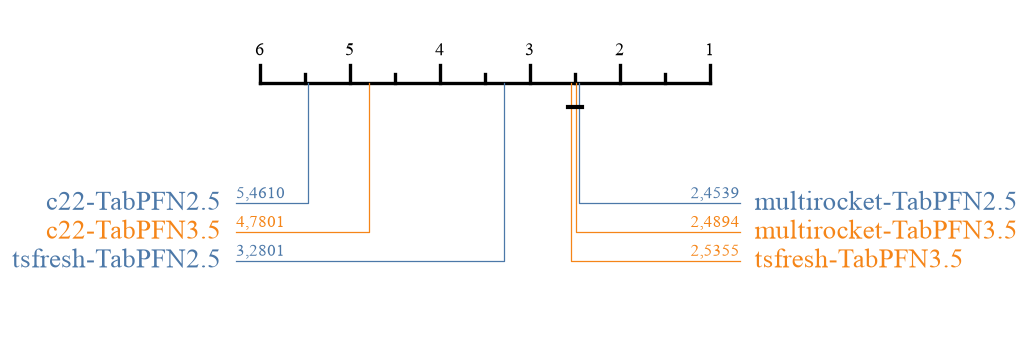

[uea] datasets used: 20


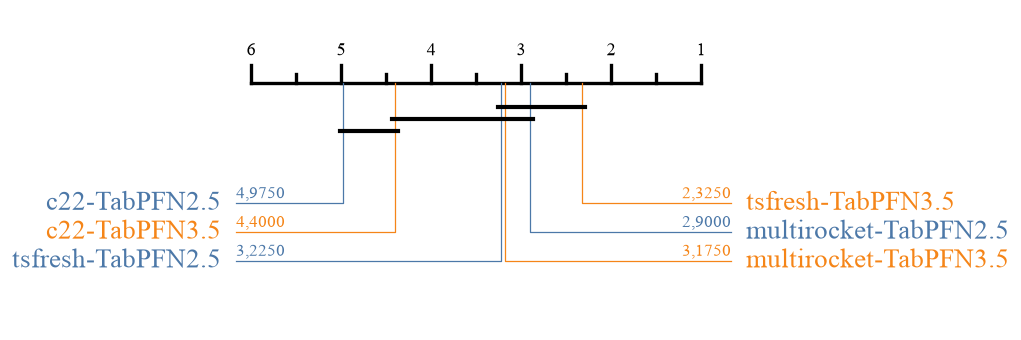

[redux] datasets used: 141 | baselines: 8 of 8 | TabPFN variants: ['multirocket-TabPFN2.5', 'multirocket-TabPFN3.5']


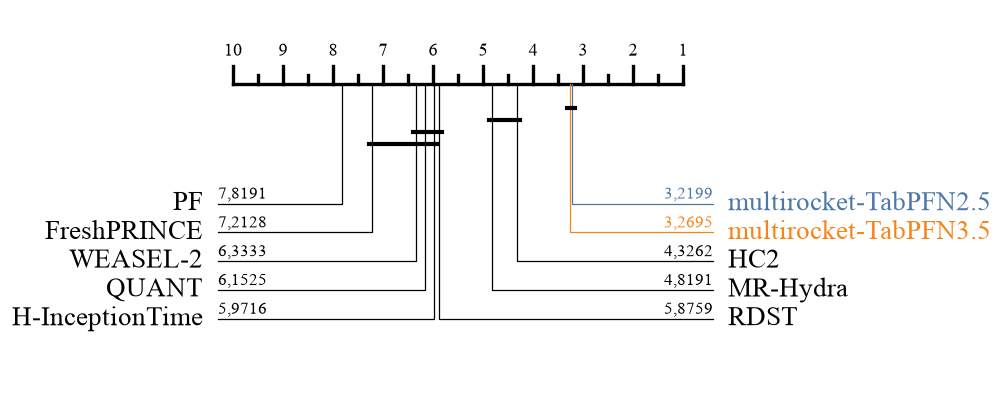

[uea] datasets used: 20 | baselines: 10 of 20 | TabPFN variants: ['tsfresh-TabPFN3.5', 'multirocket-TabPFN2.5']
  excluded for low dataset coverage: InceptionT (75%), MrSEQL (75%), MUSE (75%), TapNet (75%)


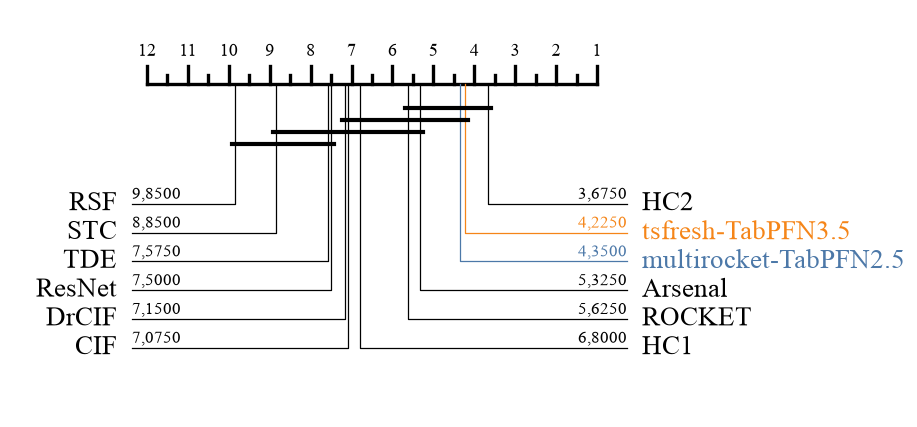

In [10]:
cd_tabpfn("redux")
cd_tabpfn("uea")
cd_vs_baselines("redux")
cd_vs_baselines("uea")


## 3.2.2 Desempenho com Poucos Exemplos

[redux] datasets in few-shot: 141 | valid in ALL methods/K: 107
  K=1: 141 valid datasets
  K=3: 132 valid datasets
  K=5: 126 valid datasets
  K=10: 107 valid datasets


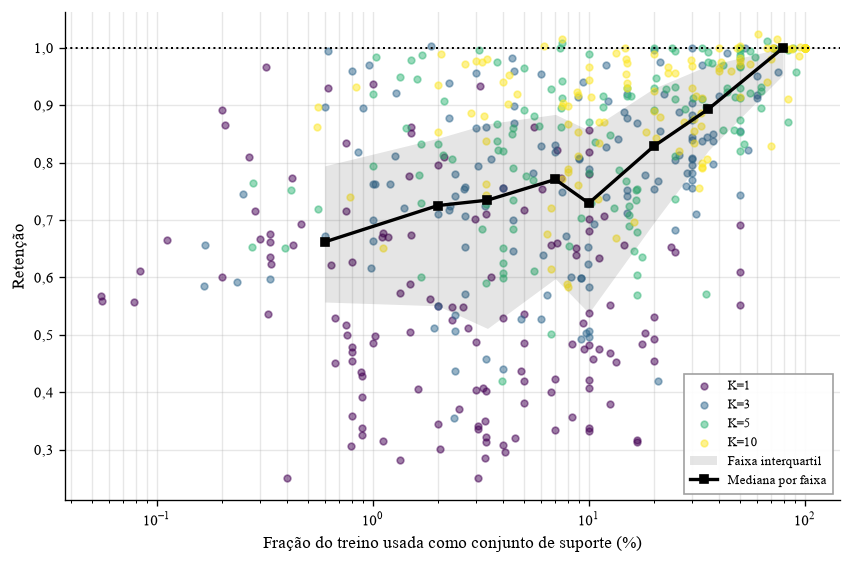

[uea] datasets in few-shot: 20 | valid in ALL methods/K: 14
  K=1: 20 valid datasets
  K=3: 19 valid datasets
  K=5: 18 valid datasets
  K=10: 14 valid datasets


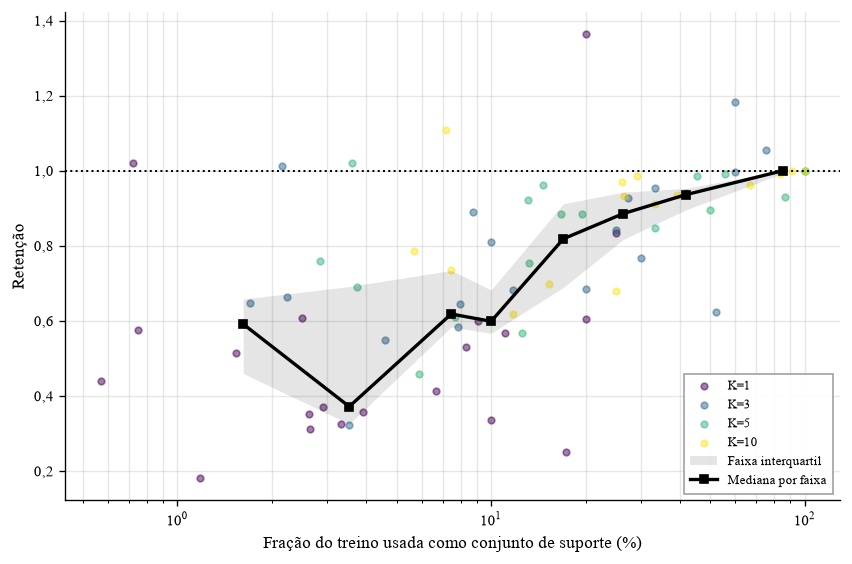

In [11]:
plot_sample_efficiency("redux", "random")
plot_sample_efficiency("uea", "random")


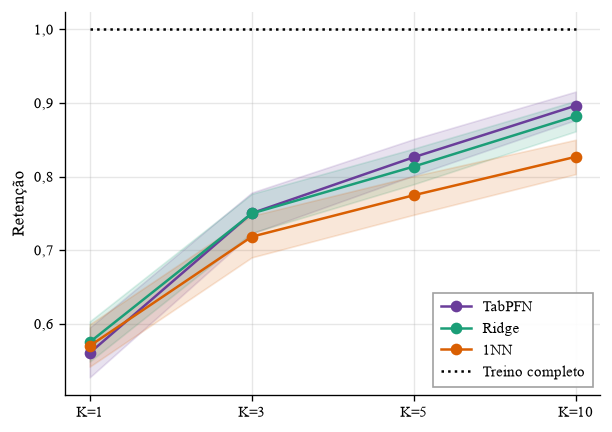

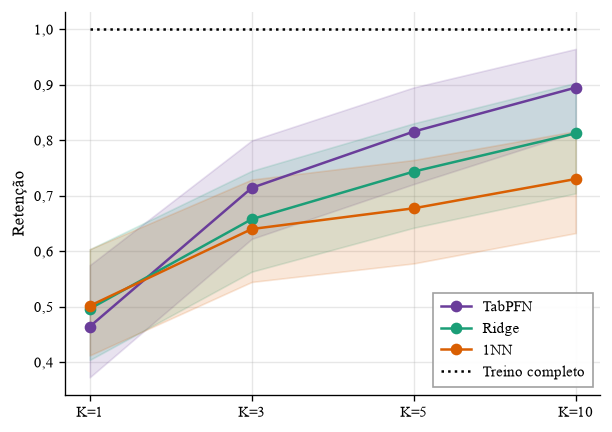

In [12]:
plot_models_vs_k("redux")
plot_models_vs_k("uea")


## 3.2.3 Efeito da Seleção do Conjunto de Suporte

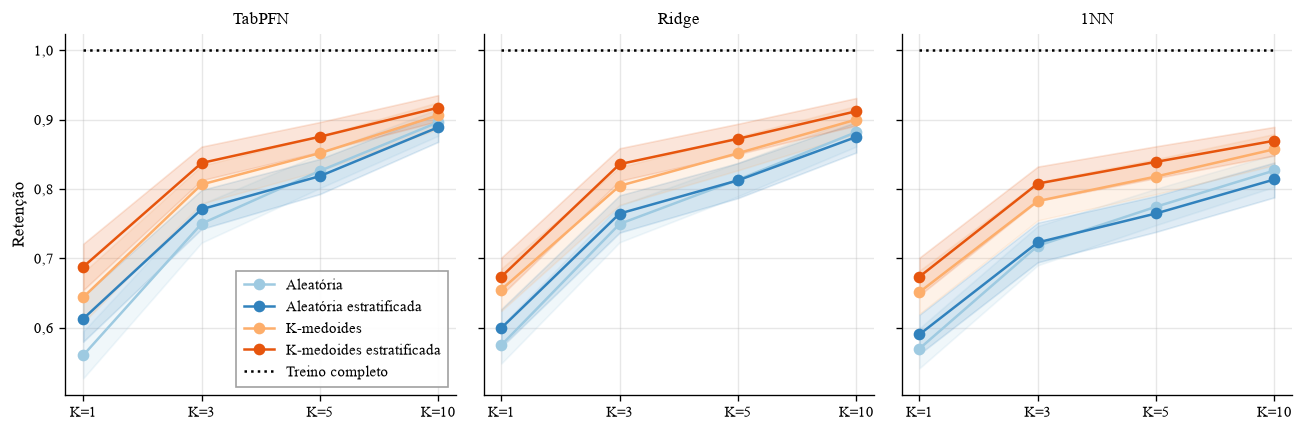

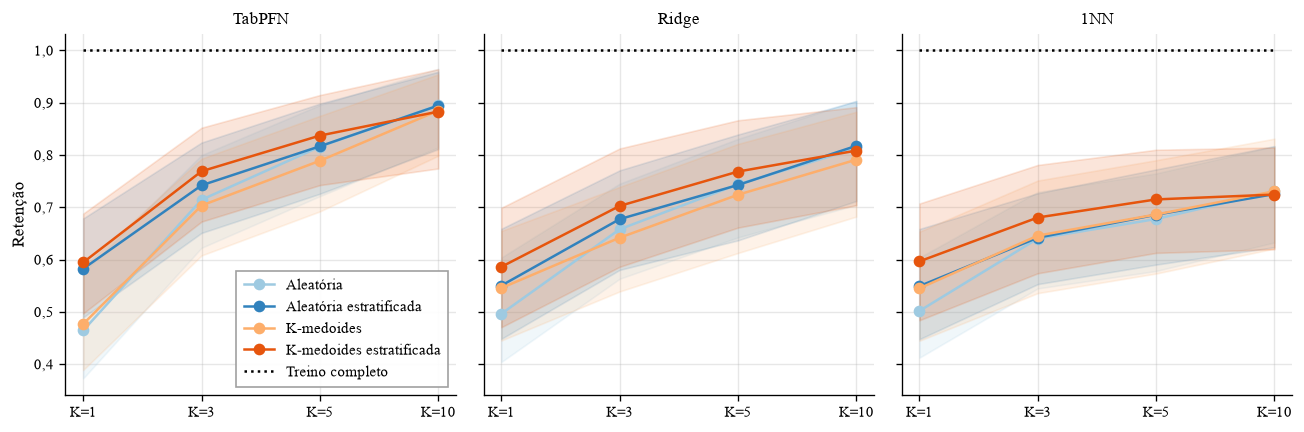

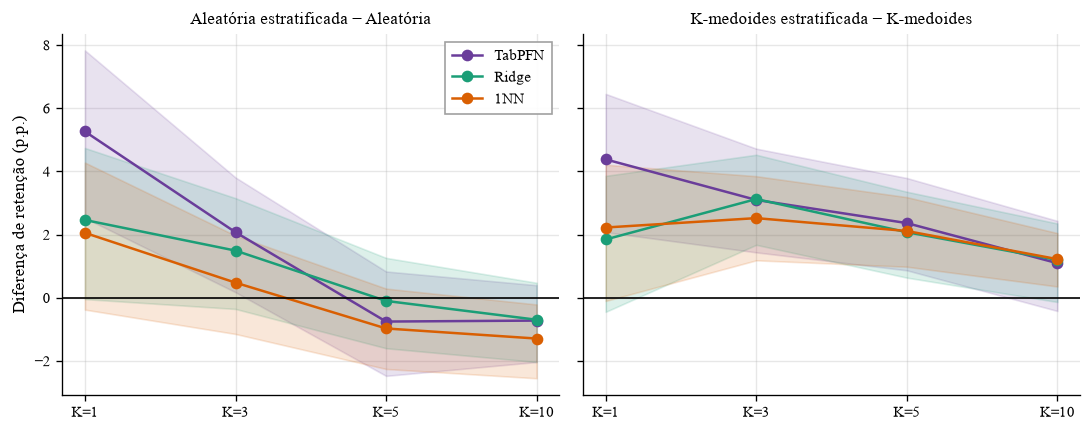

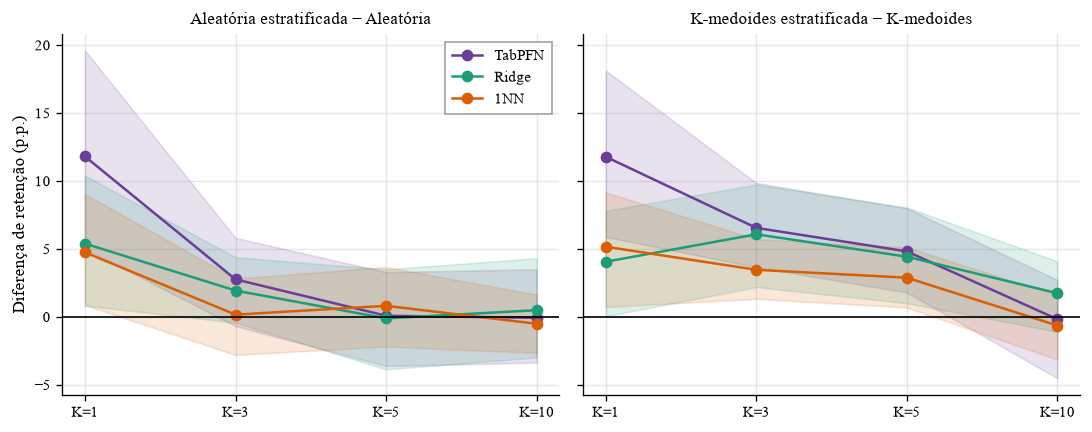

In [13]:
plot_selection_by_model("redux")
plot_selection_by_model("uea")
plot_label_gap("redux")
plot_label_gap("uea")


## 3.2.4 Custo Computacional

MED redux fit [10.88  4.72  4.71  4.72  4.76] predict [9.07 2.54 2.63 2.7  2.86] extraction 5.4


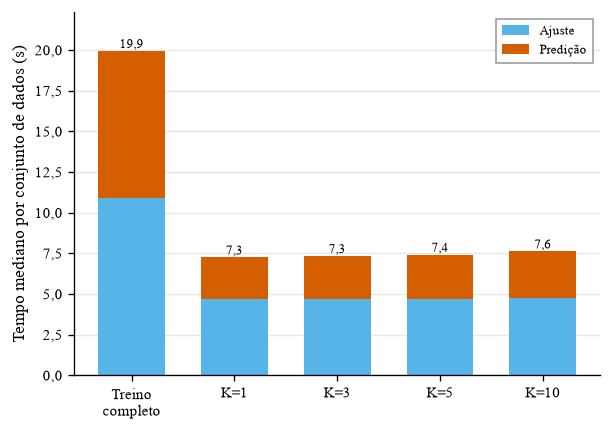

MED uea fit [2.4  2.12 2.11 2.1  2.14] predict [1.45 0.42 0.43 0.43 0.42] extraction 108.8


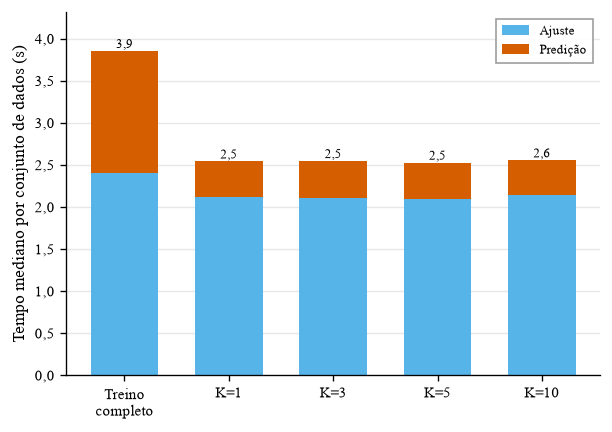

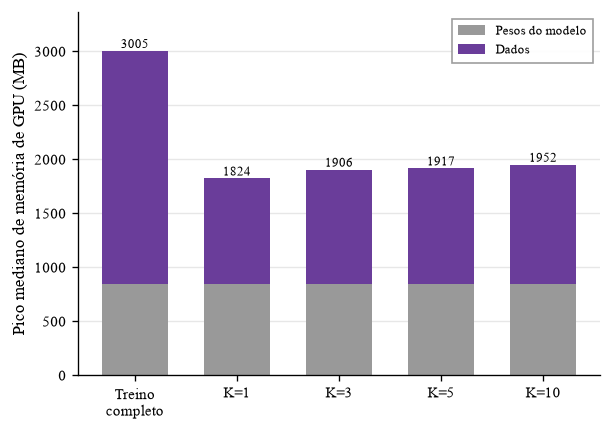

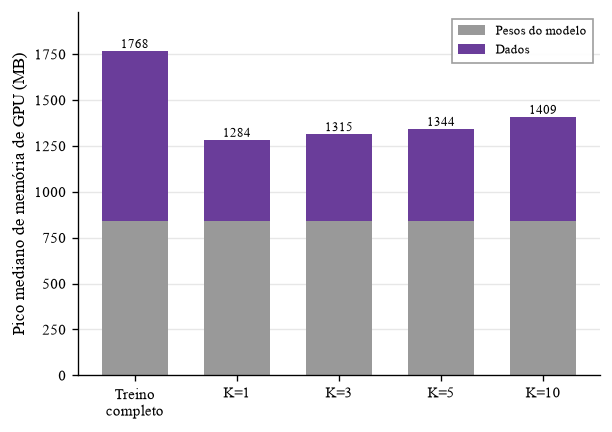

In [14]:
plot_cost_time("redux")
plot_cost_time("uea")
plot_cost_memory("redux")
plot_cost_memory("uea")


## 3.2.5 Comparação com a Literatura

[redux] literature comparison: 107 datasets, 8 classifiers


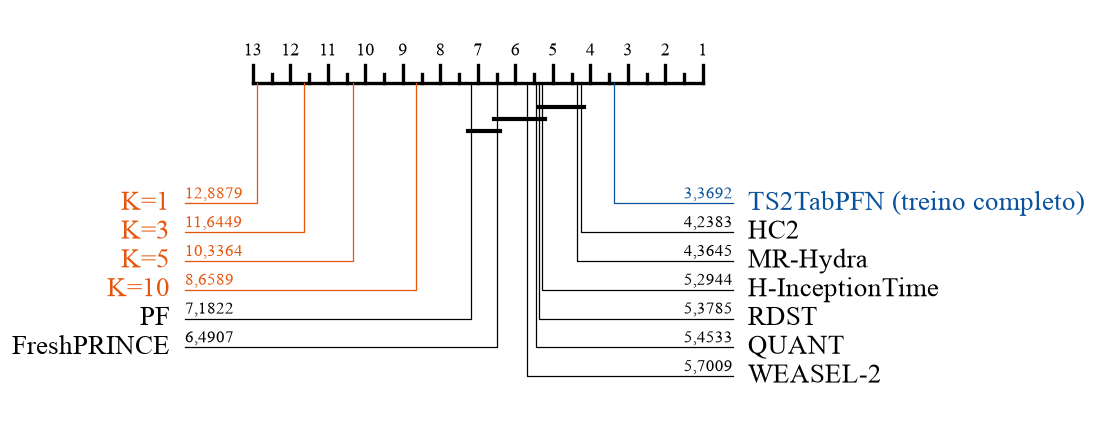

[uea] literature comparison: 14 datasets, 10 classifiers


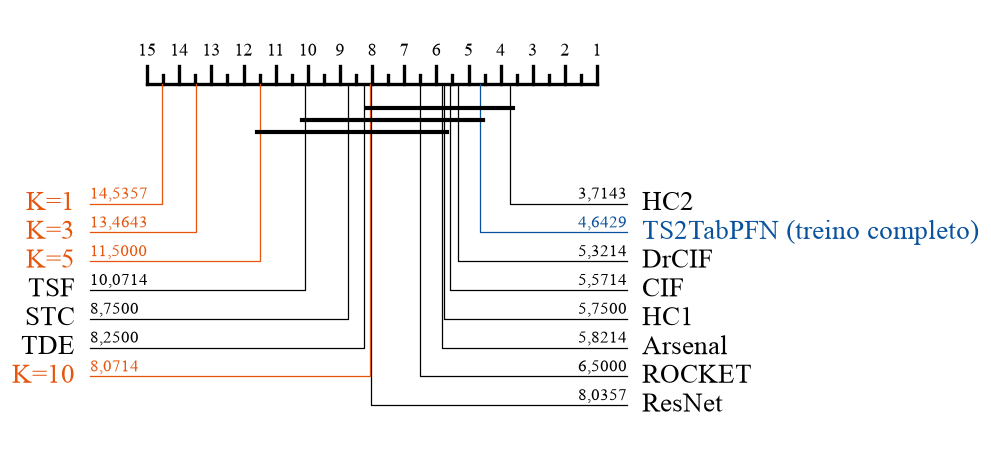

In [15]:
plot_vs_literature("redux")
plot_vs_literature("uea")
